# Generate the aligned 80 m cell mapping for the new Nairobi experiment

This notebook performs the next step after creating:

```text
Nrb_reference_binary_aligned_to_s2_80m.tif
```

It does **not** repeat majority aggregation and does **not** create a new random
train/validation/test split.

It uses the existing verified `patch_index_mapping.csv` as the authoritative
patch membership and order, then assigns the new aligned 80 m labels to the
corresponding S2 encoder output positions.

## Fixed rules

- Existing patch split remains unchanged: 306 train, 102 validation, 102 test.
- Each patch contains 16 × 16 model-output positions.
- Each position receives one label from the aligned 80 m reference.
- `-1` means invalid/background/padding and is excluded later with a valid-label mask.
- `0` means non-informal.
- `1` means informal built-up.
- The new CSV records labels and spatial addresses; it does not create labels.

In [1]:
# ============================================================
# 1. IMPORTS AND PATH SETTINGS
# ============================================================

from pathlib import Path
from datetime import datetime
import json
import math
import shutil

import numpy as np
import pandas as pd
import rasterio
from affine import Affine


CODE_ROOT = Path(r"F:\Master Research Thesis\Code")
MAPPING_ROOT = CODE_ROOT / "Mapping_Generation"

# Use the specific verified historical mapping run, not an ambiguous latest folder.
OLD_MAPPING_DIR = (
    MAPPING_ROOT
    / "outputs"
    / "run_20260710_142522"
)

PATCH_MAPPING_FILE = (
    OLD_MAPPING_DIR
    / "patch_index_mapping.csv"
)

OLD_CELL_MAPPING_FILE = (
    OLD_MAPPING_DIR
    / "cell_index_mapping.csv"
)

S2_RASTER_FILE = (
    CODE_ROOT
    / "Satellite_branch"
    / "Nrb_sentinel2_extent3857.tif"
)

REFERENCE_DIR = (
    MAPPING_ROOT
    / "reference_alignment_v2"
)

ALIGNED_LABEL_FILE = (
    REFERENCE_DIR
    / "Nrb_reference_binary_aligned_to_s2_80m.tif"
)

INFORMAL_FRACTION_FILE = (
    REFERENCE_DIR
    / "Nrb_informal_fraction_aligned_to_s2_80m.tif"
)

VALID_COUNT_FILE = (
    REFERENCE_DIR
    / "Nrb_valid_pixel_count_aligned_to_s2_80m.tif"
)

RUN_ID = datetime.now().strftime("%Y%m%d_%H%M%S")

OUT_DIR = (
    MAPPING_ROOT
    / "outputs"
    / f"aligned_mapping_v2_run_{RUN_ID}"
)

OUT_DIR.mkdir(parents=True, exist_ok=True)

print("OUT_DIR:", OUT_DIR)

required_paths = [
    PATCH_MAPPING_FILE,
    S2_RASTER_FILE,
    ALIGNED_LABEL_FILE,
    INFORMAL_FRACTION_FILE,
    VALID_COUNT_FILE,
]

for path in required_paths:
    print(path, "exists:", path.exists())

missing_paths = [
    path for path in required_paths
    if not path.exists()
]

if missing_paths:
    raise FileNotFoundError(
        "Missing required files:\n"
        + "\n".join(str(path) for path in missing_paths)
    )

OUT_DIR: F:\Master Research Thesis\Code\Mapping_Generation\outputs\aligned_mapping_v2_run_20260729_175945
F:\Master Research Thesis\Code\Mapping_Generation\outputs\run_20260710_142522\patch_index_mapping.csv exists: True
F:\Master Research Thesis\Code\Satellite_branch\Nrb_sentinel2_extent3857.tif exists: True
F:\Master Research Thesis\Code\Mapping_Generation\reference_alignment_v2\Nrb_reference_binary_aligned_to_s2_80m.tif exists: True
F:\Master Research Thesis\Code\Mapping_Generation\reference_alignment_v2\Nrb_informal_fraction_aligned_to_s2_80m.tif exists: True
F:\Master Research Thesis\Code\Mapping_Generation\reference_alignment_v2\Nrb_valid_pixel_count_aligned_to_s2_80m.tif exists: True


In [2]:
# ============================================================
# 2. CONSTANTS
# ============================================================

S2_PATCH_SIZE_PIXELS = 128
ENCODER_DOWNSAMPLE_FACTOR = 8
CELLS_PER_PATCH_SIDE = 16

S2_CELL_SIZE_M = 10.0
MODEL_CELL_SIZE_M = 80.0
PATCH_SIZE_M = 1280.0

LABEL_NODATA = -1
NON_INFORMAL_LABEL = 0
INFORMAL_LABEL = 1

SPLIT_ORDER = {
    "train": 0,
    "val": 1,
    "test": 2,
}

EXPECTED_PATCH_COUNTS = {
    "train": 306,
    "val": 102,
    "test": 102,
}

assert (
    S2_PATCH_SIZE_PIXELS
    // ENCODER_DOWNSAMPLE_FACTOR
    == CELLS_PER_PATCH_SIDE
)

assert np.isclose(
    S2_CELL_SIZE_M
    * ENCODER_DOWNSAMPLE_FACTOR,
    MODEL_CELL_SIZE_M,
)

In [3]:
# ============================================================
# 3. LOAD AND VALIDATE THE EXISTING PATCH MAPPING
# ============================================================

patch_df = pd.read_csv(PATCH_MAPPING_FILE)

required_patch_columns = {
    "split",
    "patch_order",
    "original_patch_index",
    "patch_row",
    "patch_col",
    "xmin",
    "ymin",
    "xmax",
    "ymax",
}

missing_columns = (
    required_patch_columns
    - set(patch_df.columns)
)

if missing_columns:
    raise ValueError(
        "patch_index_mapping.csv is missing columns: "
        f"{sorted(missing_columns)}"
    )

integer_columns = [
    "patch_order",
    "original_patch_index",
    "patch_row",
    "patch_col",
]

for column in integer_columns:
    patch_df[column] = (
        patch_df[column]
        .astype(int)
    )

unexpected_splits = (
    set(patch_df["split"].unique())
    - set(SPLIT_ORDER)
)

if unexpected_splits:
    raise ValueError(
        "Unexpected split values: "
        f"{sorted(unexpected_splits)}"
    )

if patch_df.duplicated(
    ["patch_row", "patch_col"]
).any():
    raise ValueError(
        "Duplicate patch_row/patch_col combinations found."
    )

if patch_df.duplicated(
    ["split", "patch_order"]
).any():
    raise ValueError(
        "Duplicate split/patch_order combinations found."
    )

patch_count_df = (
    patch_df
    .groupby("split")
    .size()
    .rename("patches")
    .reset_index()
)

print("Patch counts:")
display(patch_count_df)

for split, expected_count in EXPECTED_PATCH_COUNTS.items():
    actual_count = int(
        (patch_df["split"] == split).sum()
    )

    if actual_count != expected_count:
        raise ValueError(
            f"{split}: expected {expected_count} patches, "
            f"found {actual_count}."
        )

    orders = np.sort(
        patch_df.loc[
            patch_df["split"] == split,
            "patch_order",
        ].to_numpy()
    )

    expected_orders = np.arange(
        expected_count,
        dtype=int,
    )

    if not np.array_equal(
        orders,
        expected_orders,
    ):
        raise ValueError(
            f"{split}: patch_order is not contiguous "
            f"from 0 to {expected_count - 1}."
        )

print("Existing patch split and order validated.")

Patch counts:


,split,patches
0,test,102
1,train,306
2,val,102


Existing patch split and order validated.


In [4]:
# ============================================================
# 4. LOAD AND VALIDATE THE S2 AND 80 M RASTERS
# ============================================================

with rasterio.open(S2_RASTER_FILE) as s2_src:
    s2_height = s2_src.height
    s2_width = s2_src.width
    s2_crs = s2_src.crs
    s2_transform = s2_src.transform
    s2_bounds = s2_src.bounds

with rasterio.open(ALIGNED_LABEL_FILE) as label_src:
    label_array = label_src.read(1).astype(np.int8)
    label_height = label_src.height
    label_width = label_src.width
    label_crs = label_src.crs
    label_transform = label_src.transform
    label_nodata = label_src.nodata

with rasterio.open(INFORMAL_FRACTION_FILE) as fraction_src:
    informal_fraction_array = (
        fraction_src.read(1)
        .astype(np.float32)
    )
    fraction_transform = fraction_src.transform
    fraction_crs = fraction_src.crs

with rasterio.open(VALID_COUNT_FILE) as count_src:
    valid_count_array = (
        count_src.read(1)
        .astype(np.uint8)
    )
    count_transform = count_src.transform
    count_crs = count_src.crs

expected_80m_transform = (
    s2_transform
    * Affine.scale(
        ENCODER_DOWNSAMPLE_FACTOR,
        ENCODER_DOWNSAMPLE_FACTOR,
    )
)

print("S2 shape:", (s2_height, s2_width))
print("S2 CRS:", s2_crs)
print("S2 transform:", s2_transform)
print("Aligned label shape:", (label_height, label_width))
print("Aligned label CRS:", label_crs)
print("Aligned label transform:", label_transform)
print("Aligned label NoData:", label_nodata)
print("Aligned label values:", np.unique(label_array))

if s2_crs != label_crs:
    raise ValueError(
        "S2 and aligned label CRS values do not match."
    )

if not np.allclose(
    tuple(label_transform)[:6],
    tuple(expected_80m_transform)[:6],
    atol=1e-8,
):
    raise ValueError(
        "The aligned 80 m label transform does not match "
        "the S2-derived 80 m transform."
    )

if (
    fraction_crs != label_crs
    or count_crs != label_crs
):
    raise ValueError(
        "Auxiliary rasters do not use the same CRS "
        "as the aligned label raster."
    )

if not np.allclose(
    tuple(fraction_transform)[:6],
    tuple(label_transform)[:6],
    atol=1e-8,
):
    raise ValueError(
        "Informal-fraction raster is not aligned "
        "with the label raster."
    )

if not np.allclose(
    tuple(count_transform)[:6],
    tuple(label_transform)[:6],
    atol=1e-8,
):
    raise ValueError(
        "Valid-count raster is not aligned "
        "with the label raster."
    )

if informal_fraction_array.shape != label_array.shape:
    raise ValueError(
        "Informal-fraction shape does not match "
        "the label shape."
    )

if valid_count_array.shape != label_array.shape:
    raise ValueError(
        "Valid-count shape does not match "
        "the label shape."
    )

unexpected_labels = (
    set(np.unique(label_array).tolist())
    - {-1, 0, 1}
)

if unexpected_labels:
    raise ValueError(
        "Unexpected aligned labels: "
        f"{sorted(unexpected_labels)}"
    )

print("Raster alignment validation passed.")

S2 shape: (3160, 4897)
S2 CRS: EPSG:3857
S2 transform: | 10.00, 0.00, 4081450.00|
| 0.00,-10.00,-129210.00|
| 0.00, 0.00, 1.00|
Aligned label shape: (395, 612)
Aligned label CRS: EPSG:3857
Aligned label transform: | 80.00, 0.00, 4081450.00|
| 0.00,-80.00,-129210.00|
| 0.00, 0.00, 1.00|
Aligned label NoData: -1.0
Aligned label values: [-1  0  1]
Raster alignment validation passed.


In [5]:
# ============================================================
# 4A. INDEPENDENTLY VERIFY THE OLD PATCH SPLIT AND ORDER
# ============================================================
#
# This is the formal validation step.
#
# It compares two independently stored records of the old split:
#
# 1. patch_index_mapping.csv
# 2. train/val/test_original_patch_indices.npy
#
# Exact equality means that every patch has the same:
# - split membership
# - position within the split (patch_order)
# - original row-major patch index
# - patch_row and patch_col on the S2 patch grid
#
# The new aligned labels are not involved in this comparison.

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch


ARCHIVED_INDEX_FILES = {
    "train": (
        OLD_MAPPING_DIR
        / "train_original_patch_indices.npy"
    ),
    "val": (
        OLD_MAPPING_DIR
        / "val_original_patch_indices.npy"
    ),
    "test": (
        OLD_MAPPING_DIR
        / "test_original_patch_indices.npy"
    ),
}

missing_archive_files = [
    path
    for path in ARCHIVED_INDEX_FILES.values()
    if not path.exists()
]

if missing_archive_files:
    raise FileNotFoundError(
        "The independent archived split-index files "
        "are required for formal validation:\n"
        + "\n".join(
            str(path)
            for path in missing_archive_files
        )
    )

patch_grid_rows_for_validation = math.ceil(
    s2_height
    / S2_PATCH_SIZE_PIXELS
)

patch_grid_cols_for_validation = math.ceil(
    s2_width
    / S2_PATCH_SIZE_PIXELS
)

total_full_grid_patches = (
    patch_grid_rows_for_validation
    * patch_grid_cols_for_validation
)

print(
    "Full S2 patch grid:",
    (
        patch_grid_rows_for_validation,
        patch_grid_cols_for_validation,
    ),
)

print(
    "Total row-major patch positions:",
    total_full_grid_patches,
)

archive_records = []
validation_records = []

for split in ["train", "val", "test"]:
    archived_indices = np.load(
        ARCHIVED_INDEX_FILES[split]
    ).astype(int)

    csv_split = (
        patch_df.loc[
            patch_df["split"] == split
        ]
        .sort_values("patch_order")
        .reset_index(drop=True)
    )

    csv_indices = (
        csv_split[
            "original_patch_index"
        ]
        .to_numpy(dtype=int)
    )

    expected_orders = np.arange(
        len(archived_indices),
        dtype=int,
    )

    exact_index_sequence_match = (
        np.array_equal(
            csv_indices,
            archived_indices,
        )
    )

    exact_patch_order_match = (
        np.array_equal(
            csv_split[
                "patch_order"
            ].to_numpy(dtype=int),
            expected_orders,
        )
    )

    archived_patch_rows = (
        archived_indices
        // patch_grid_cols_for_validation
    )

    archived_patch_cols = (
        archived_indices
        % patch_grid_cols_for_validation
    )

    exact_patch_row_match = (
        np.array_equal(
            csv_split[
                "patch_row"
            ].to_numpy(dtype=int),
            archived_patch_rows,
        )
    )

    exact_patch_col_match = (
        np.array_equal(
            csv_split[
                "patch_col"
            ].to_numpy(dtype=int),
            archived_patch_cols,
        )
    )

    validation_records.append(
        {
            "split": split,
            "csv_patch_count": len(csv_split),
            "archived_patch_count": (
                len(archived_indices)
            ),
            "exact_index_sequence_match": (
                exact_index_sequence_match
            ),
            "exact_patch_order_match": (
                exact_patch_order_match
            ),
            "exact_patch_row_match": (
                exact_patch_row_match
            ),
            "exact_patch_col_match": (
                exact_patch_col_match
            ),
        }
    )

    if not exact_index_sequence_match:
        mismatch_positions = np.flatnonzero(
            csv_indices
            != archived_indices
        )

        raise AssertionError(
            f"{split}: original_patch_index sequence "
            f"does not match at "
            f"{len(mismatch_positions)} positions. "
            f"First mismatches: "
            f"{mismatch_positions[:10].tolist()}"
        )

    if not exact_patch_order_match:
        raise AssertionError(
            f"{split}: patch_order does not match "
            "the archived sequence."
        )

    if not exact_patch_row_match:
        raise AssertionError(
            f"{split}: patch_row is inconsistent "
            "with original_patch_index."
        )

    if not exact_patch_col_match:
        raise AssertionError(
            f"{split}: patch_col is inconsistent "
            "with original_patch_index."
        )

    for patch_order, original_patch_index in enumerate(
        archived_indices
    ):
        archive_records.append(
            {
                "split": split,
                "patch_order": int(
                    patch_order
                ),
                "original_patch_index": int(
                    original_patch_index
                ),
                "patch_row": int(
                    original_patch_index
                    // patch_grid_cols_for_validation
                ),
                "patch_col": int(
                    original_patch_index
                    % patch_grid_cols_for_validation
                ),
            }
        )

validation_df = pd.DataFrame(
    validation_records
)

archive_patch_df = pd.DataFrame(
    archive_records
)

all_archived_indices = (
    archive_patch_df[
        "original_patch_index"
    ]
    .to_numpy(dtype=int)
)

if len(
    np.unique(
        all_archived_indices
    )
) != len(
    all_archived_indices
):
    raise AssertionError(
        "At least one archived patch appears "
        "in more than one split."
    )

if (
    all_archived_indices.min() < 0
    or all_archived_indices.max()
    >= total_full_grid_patches
):
    raise AssertionError(
        "An archived original_patch_index lies "
        "outside the full S2 patch grid."
    )

exact_record_comparison = (
    patch_df[
        [
            "split",
            "patch_order",
            "original_patch_index",
            "patch_row",
            "patch_col",
        ]
    ]
    .sort_values(
        [
            "split",
            "patch_order",
        ]
    )
    .reset_index(drop=True)
    .equals(
        archive_patch_df[
            [
                "split",
                "patch_order",
                "original_patch_index",
                "patch_row",
                "patch_col",
            ]
        ]
        .sort_values(
            [
                "split",
                "patch_order",
            ]
        )
        .reset_index(drop=True)
    )
)

if not exact_record_comparison:
    raise AssertionError(
        "The full patch records in the CSV and "
        "the independent archived index arrays "
        "are not identical."
    )

VALIDATION_SUMMARY_FILE = (
    OUT_DIR
    / "old_patch_split_exact_validation.csv"
)

validation_df.to_csv(
    VALIDATION_SUMMARY_FILE,
    index=False,
)

print("\nExact split validation:")
display(validation_df)

print(
    "\nFull record comparison:",
    exact_record_comparison,
)

print(
    "\nRESULT: the existing patch mapping "
    "matches the independently archived "
    "train/val/test indices exactly."
)

Full S2 patch grid: (25, 39)
Total row-major patch positions: 975

Exact split validation:


,split,csv_patch_count,archived_patch_count,exact_index_sequence_match,exact_patch_order_match,exact_patch_row_match,exact_patch_col_match
0,train,306,306,True,True,True,True
1,val,102,102,True,True,True,True
2,test,102,102,True,True,True,True



Full record comparison: True

RESULT: the existing patch mapping matches the independently archived train/val/test indices exactly.


Visual agreement category counts:


,category,patches
0,Out / not selected,465
1,Exact train match,306
2,Exact validation match,102
3,Exact test match,102
4,Mismatch,0


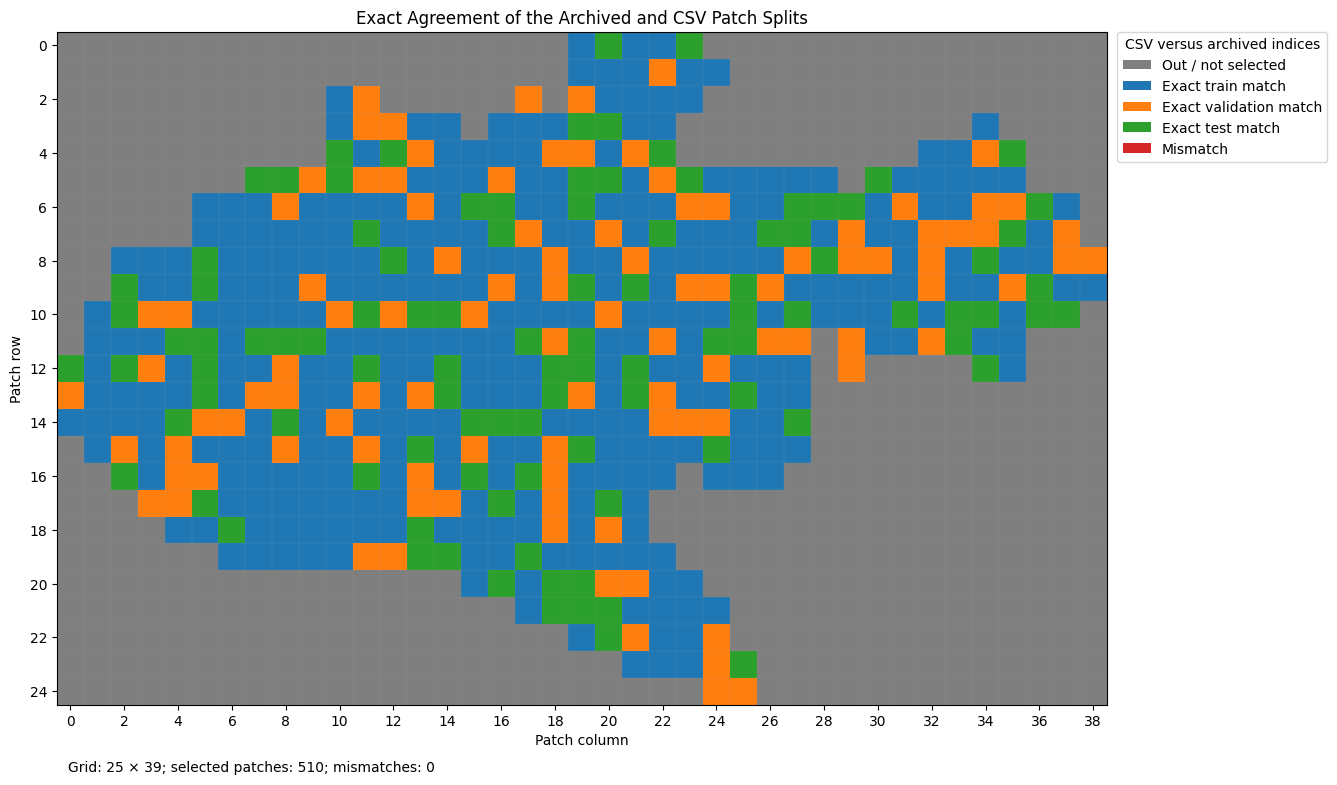

Visual agreement map saved to: F:\Master Research Thesis\Code\Mapping_Generation\outputs\aligned_mapping_v2_run_20260729_175945\old_patch_split_exact_agreement_map.png
No split-membership or patch-order mismatches were found.


In [6]:
# ============================================================
# 4B. VISUALISE PATCH-SPLIT AND PATCH-ORDER AGREEMENT
# ============================================================
#
# This map is supporting visual evidence.
#
# A patch is coloured as an exact train/val/test match only
# when BOTH sources agree on:
# - original_patch_index
# - split
# - patch_order
#
# Any disagreement is assigned to the Mismatch category.
#
# The exact array comparison in Cell 4A remains the formal proof.

csv_by_index = (
    patch_df
    .set_index(
        "original_patch_index"
    )[
        [
            "split",
            "patch_order",
        ]
    ]
    .to_dict(
        orient="index"
    )
)

archive_by_index = (
    archive_patch_df
    .set_index(
        "original_patch_index"
    )[
        [
            "split",
            "patch_order",
        ]
    ]
    .to_dict(
        orient="index"
    )
)

agreement_grid = np.zeros(
    (
        patch_grid_rows_for_validation,
        patch_grid_cols_for_validation,
    ),
    dtype=np.uint8,
)

category_codes = {
    "out": 0,
    "train": 1,
    "val": 2,
    "test": 3,
    "mismatch": 4,
}

mismatch_details = []

for original_patch_index in range(
    total_full_grid_patches
):
    patch_row = (
        original_patch_index
        // patch_grid_cols_for_validation
    )

    patch_col = (
        original_patch_index
        % patch_grid_cols_for_validation
    )

    csv_record = csv_by_index.get(
        original_patch_index
    )

    archive_record = archive_by_index.get(
        original_patch_index
    )

    if (
        csv_record is None
        and archive_record is None
    ):
        agreement_grid[
            patch_row,
            patch_col,
        ] = category_codes["out"]

        continue

    records_match = (
        csv_record is not None
        and archive_record is not None
        and csv_record["split"]
        == archive_record["split"]
        and int(
            csv_record["patch_order"]
        )
        == int(
            archive_record["patch_order"]
        )
    )

    if records_match:
        agreement_grid[
            patch_row,
            patch_col,
        ] = category_codes[
            csv_record["split"]
        ]
    else:
        agreement_grid[
            patch_row,
            patch_col,
        ] = category_codes[
            "mismatch"
        ]

        mismatch_details.append(
            {
                "original_patch_index": (
                    original_patch_index
                ),
                "patch_row": patch_row,
                "patch_col": patch_col,
                "csv_record": csv_record,
                "archive_record": (
                    archive_record
                ),
            }
        )

mismatch_count = len(
    mismatch_details
)

visual_category_counts = {
    "Out / not selected": int(
        np.sum(
            agreement_grid
            == category_codes["out"]
        )
    ),
    "Exact train match": int(
        np.sum(
            agreement_grid
            == category_codes["train"]
        )
    ),
    "Exact validation match": int(
        np.sum(
            agreement_grid
            == category_codes["val"]
        )
    ),
    "Exact test match": int(
        np.sum(
            agreement_grid
            == category_codes["test"]
        )
    ),
    "Mismatch": int(
        np.sum(
            agreement_grid
            == category_codes["mismatch"]
        )
    ),
}

print(
    "Visual agreement category counts:"
)

display(
    pd.DataFrame(
        {
            "category": list(
                visual_category_counts.keys()
            ),
            "patches": list(
                visual_category_counts.values()
            ),
        }
    )
)

base_cmap = plt.get_cmap(
    "tab10"
)

map_colours = [
    base_cmap(7),
    base_cmap(0),
    base_cmap(1),
    base_cmap(2),
    base_cmap(3),
]

agreement_cmap = ListedColormap(
    map_colours
)

agreement_norm = BoundaryNorm(
    [
        -0.5,
        0.5,
        1.5,
        2.5,
        3.5,
        4.5,
    ],
    agreement_cmap.N,
)

fig, ax = plt.subplots(
    figsize=(13, 8)
)

ax.imshow(
    agreement_grid,
    cmap=agreement_cmap,
    norm=agreement_norm,
    origin="upper",
    interpolation="nearest",
)

ax.set_title(
    "Exact Agreement of the Archived and CSV Patch Splits"
)

ax.set_xlabel(
    "Patch column"
)

ax.set_ylabel(
    "Patch row"
)

ax.set_xticks(
    np.arange(
        0,
        patch_grid_cols_for_validation,
        2,
    )
)

ax.set_yticks(
    np.arange(
        0,
        patch_grid_rows_for_validation,
        2,
    )
)

ax.set_xticks(
    np.arange(
        -0.5,
        patch_grid_cols_for_validation,
        1,
    ),
    minor=True,
)

ax.set_yticks(
    np.arange(
        -0.5,
        patch_grid_rows_for_validation,
        1,
    ),
    minor=True,
)

ax.grid(
    which="minor",
    linewidth=0.25,
    alpha=0.35,
)

ax.tick_params(
    which="minor",
    bottom=False,
    left=False,
)

legend_handles = [
    Patch(
        facecolor=map_colours[0],
        label="Out / not selected",
    ),
    Patch(
        facecolor=map_colours[1],
        label="Exact train match",
    ),
    Patch(
        facecolor=map_colours[2],
        label="Exact validation match",
    ),
    Patch(
        facecolor=map_colours[3],
        label="Exact test match",
    ),
    Patch(
        facecolor=map_colours[4],
        label="Mismatch",
    ),
]

ax.legend(
    handles=legend_handles,
    title=(
        "CSV versus archived indices"
    ),
    loc="upper left",
    bbox_to_anchor=(
        1.01,
        1.0,
    ),
    borderaxespad=0,
)

ax.text(
    0.01,
    -0.10,
    (
        f"Grid: "
        f"{patch_grid_rows_for_validation}"
        f" × "
        f"{patch_grid_cols_for_validation}; "
        f"selected patches: {len(patch_df)}; "
        f"mismatches: {mismatch_count}"
    ),
    transform=ax.transAxes,
)

plt.tight_layout()

PATCH_AGREEMENT_FIGURE = (
    OUT_DIR
    / "old_patch_split_exact_agreement_map.png"
)

fig.savefig(
    PATCH_AGREEMENT_FIGURE,
    dpi=300,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

if mismatch_count != 0:
    mismatch_df = pd.DataFrame(
        mismatch_details
    )

    mismatch_df.to_csv(
        OUT_DIR
        / "old_patch_split_mismatches.csv",
        index=False,
    )

    raise AssertionError(
        f"The visual agreement map contains "
        f"{mismatch_count} mismatched patches."
    )

print(
    "Visual agreement map saved to:",
    PATCH_AGREEMENT_FIGURE,
)

print(
    "No split-membership or patch-order "
    "mismatches were found."
)

In [7]:
# ============================================================
# 5. CREATE THE MODEL-INDEX GRID AND PAD WITH INVALID VALUES
# ============================================================

# The S2 model processes complete 128 × 128 patches.
patch_grid_rows = math.ceil(
    s2_height
    / S2_PATCH_SIZE_PIXELS
)

patch_grid_cols = math.ceil(
    s2_width
    / S2_PATCH_SIZE_PIXELS
)

model_grid_rows = (
    patch_grid_rows
    * CELLS_PER_PATCH_SIDE
)

model_grid_cols = (
    patch_grid_cols
    * CELLS_PER_PATCH_SIDE
)

print("Full patch grid:", (patch_grid_rows, patch_grid_cols))
print("Full model cell grid:", (model_grid_rows, model_grid_cols))
print("Physical 80 m label grid:", label_array.shape)

if (
    label_height > model_grid_rows
    or label_width > model_grid_cols
):
    raise ValueError(
        "The physical label grid is larger than "
        "the model-index grid."
    )

# Invalid/padding positions are explicitly -1.
padded_label_array = np.full(
    (model_grid_rows, model_grid_cols),
    LABEL_NODATA,
    dtype=np.int8,
)

padded_fraction_array = np.full(
    (model_grid_rows, model_grid_cols),
    -1.0,
    dtype=np.float32,
)

padded_valid_count_array = np.zeros(
    (model_grid_rows, model_grid_cols),
    dtype=np.uint8,
)

padded_label_array[
    :label_height,
    :label_width,
] = label_array

padded_fraction_array[
    :label_height,
    :label_width,
] = informal_fraction_array

padded_valid_count_array[
    :label_height,
    :label_width,
] = valid_count_array

print(
    "Rows added as invalid model padding:",
    model_grid_rows - label_height,
)

print(
    "Columns added as invalid model padding:",
    model_grid_cols - label_width,
)

print(
    "Padded label values:",
    np.unique(padded_label_array),
)

# Save the padded model-index rasters as NumPy arrays for audit.
np.save(
    OUT_DIR
    / "padded_reference_labels_400x624.npy",
    padded_label_array,
)

np.save(
    OUT_DIR
    / "padded_informal_fraction_400x624.npy",
    padded_fraction_array,
)

np.save(
    OUT_DIR
    / "padded_valid_10m_count_400x624.npy",
    padded_valid_count_array,
)

Full patch grid: (25, 39)
Full model cell grid: (400, 624)
Physical 80 m label grid: (395, 612)
Rows added as invalid model padding: 5
Columns added as invalid model padding: 12
Padded label values: [-1  0  1]


In [8]:
# ============================================================
# 6. VERIFY PATCH BOUNDS AGAINST THE S2 GRID
# ============================================================

origin_x = float(s2_transform.c)
origin_y = float(s2_transform.f)

patch_bounds_check = patch_df.copy()

patch_bounds_check["expected_xmin"] = (
    origin_x
    + patch_bounds_check["patch_col"]
    * PATCH_SIZE_M
)

patch_bounds_check["expected_xmax"] = (
    patch_bounds_check["expected_xmin"]
    + PATCH_SIZE_M
)

patch_bounds_check["expected_ymax"] = (
    origin_y
    - patch_bounds_check["patch_row"]
    * PATCH_SIZE_M
)

patch_bounds_check["expected_ymin"] = (
    patch_bounds_check["expected_ymax"]
    - PATCH_SIZE_M
)

bound_checks = {
    "xmin": "expected_xmin",
    "xmax": "expected_xmax",
    "ymin": "expected_ymin",
    "ymax": "expected_ymax",
}

for actual_column, expected_column in bound_checks.items():
    if not np.allclose(
        patch_bounds_check[actual_column],
        patch_bounds_check[expected_column],
        atol=1e-6,
    ):
        mismatch = patch_bounds_check.loc[
            ~np.isclose(
                patch_bounds_check[actual_column],
                patch_bounds_check[expected_column],
                atol=1e-6,
            )
        ]

        raise ValueError(
            f"Patch-bound mismatch in {actual_column}. "
            f"Affected patches: {len(mismatch)}"
        )

print("Existing patch bounds match the S2 grid.")

Existing patch bounds match the S2 grid.


In [9]:
# ============================================================
# 7. GENERATE cell_index_mapping_v2.csv
# ============================================================

cell_records = []

ordered_patch_df = (
    patch_df
    .assign(
        _split_order=patch_df["split"].map(SPLIT_ORDER)
    )
    .sort_values(
        ["_split_order", "patch_order"]
    )
    .drop(columns="_split_order")
    .reset_index(drop=True)
)

for patch in ordered_patch_df.itertuples(index=False):
    split = str(patch.split)
    patch_order = int(patch.patch_order)
    patch_row = int(patch.patch_row)
    patch_col = int(patch.patch_col)

    for cell_row in range(CELLS_PER_PATCH_SIDE):
        for cell_col in range(CELLS_PER_PATCH_SIDE):
            global_cell_row = (
                patch_row
                * CELLS_PER_PATCH_SIDE
                + cell_row
            )

            global_cell_col = (
                patch_col
                * CELLS_PER_PATCH_SIDE
                + cell_col
            )

            reference_label = int(
                padded_label_array[
                    global_cell_row,
                    global_cell_col,
                ]
            )

            informal_fraction = float(
                padded_fraction_array[
                    global_cell_row,
                    global_cell_col,
                ]
            )

            valid_10m_pixel_count = int(
                padded_valid_count_array[
                    global_cell_row,
                    global_cell_col,
                ]
            )

            valid_cell = (
                reference_label
                in {
                    NON_INFORMAL_LABEL,
                    INFORMAL_LABEL,
                }
            )

            row_index_in_split = (
                patch_order
                * (
                    CELLS_PER_PATCH_SIDE
                    ** 2
                )
                + cell_row
                * CELLS_PER_PATCH_SIDE
                + cell_col
            )

            cell_xmin = (
                origin_x
                + global_cell_col
                * MODEL_CELL_SIZE_M
            )

            cell_xmax = (
                cell_xmin
                + MODEL_CELL_SIZE_M
            )

            cell_ymax = (
                origin_y
                - global_cell_row
                * MODEL_CELL_SIZE_M
            )

            cell_ymin = (
                cell_ymax
                - MODEL_CELL_SIZE_M
            )

            cell_records.append(
                {
                    "split": split,
                    "patch_order": patch_order,
                    "original_patch_index": int(
                        patch.original_patch_index
                    ),
                    "patch_row": patch_row,
                    "patch_col": patch_col,
                    "cell_row": cell_row,
                    "cell_col": cell_col,
                    "global_cell_row": global_cell_row,
                    "global_cell_col": global_cell_col,
                    "row_index_in_split": (
                        row_index_in_split
                    ),
                    "reference_label": reference_label,
                    # Compatibility alias for older scripts.
                    "label": reference_label,
                    "valid_cell": bool(valid_cell),
                    "informal_fraction": (
                        informal_fraction
                    ),
                    "valid_10m_pixel_count": (
                        valid_10m_pixel_count
                    ),
                    "valid_coverage_fraction": (
                        valid_10m_pixel_count
                        / 64.0
                    ),
                    "is_padding_or_nodata": (
                        not valid_cell
                    ),
                    "xmin": cell_xmin,
                    "ymin": cell_ymin,
                    "xmax": cell_xmax,
                    "ymax": cell_ymax,
                }
            )

cell_df_v2 = pd.DataFrame(
    cell_records
)

if cell_df_v2.duplicated(
    [
        "patch_row",
        "patch_col",
        "cell_row",
        "cell_col",
    ]
).any():
    raise ValueError(
        "Duplicate spatial cell keys found."
    )

if cell_df_v2.duplicated(
    [
        "split",
        "row_index_in_split",
    ]
).any():
    raise ValueError(
        "Duplicate split/row_index_in_split values found."
    )

expected_cell_rows = (
    len(patch_df)
    * (
        CELLS_PER_PATCH_SIDE
        ** 2
    )
)

if len(cell_df_v2) != expected_cell_rows:
    raise ValueError(
        f"Expected {expected_cell_rows} cell rows, "
        f"found {len(cell_df_v2)}."
    )

CELL_MAPPING_V2_FILE = (
    OUT_DIR
    / "cell_index_mapping_v2.csv"
)

PATCH_MAPPING_COPY_FILE = (
    OUT_DIR
    / "patch_index_mapping.csv"
)

cell_df_v2.to_csv(
    CELL_MAPPING_V2_FILE,
    index=False,
)

patch_df.to_csv(
    PATCH_MAPPING_COPY_FILE,
    index=False,
)

print("Saved:", CELL_MAPPING_V2_FILE)
print("Saved:", PATCH_MAPPING_COPY_FILE)

display(cell_df_v2.head())

Saved: F:\Master Research Thesis\Code\Mapping_Generation\outputs\aligned_mapping_v2_run_20260729_175945\cell_index_mapping_v2.csv
Saved: F:\Master Research Thesis\Code\Mapping_Generation\outputs\aligned_mapping_v2_run_20260729_175945\patch_index_mapping.csv


,split,patch_order,original_patch_index,patch_row,patch_col,cell_row,cell_col,global_cell_row,global_cell_col,row_index_in_split,...,label,valid_cell,informal_fraction,valid_10m_pixel_count,valid_coverage_fraction,is_padding_or_nodata,xmin,ymin,xmax,ymax
0,train,0,281,7,8,0,0,112,128,0,...,0,True,0.0,64,1.0,False,4091690.0,-138250.0,4091770.0,-138170.0
1,train,0,281,7,8,0,1,112,129,1,...,0,True,0.0,64,1.0,False,4091770.0,-138250.0,4091850.0,-138170.0
2,train,0,281,7,8,0,2,112,130,2,...,0,True,0.0,64,1.0,False,4091850.0,-138250.0,4091930.0,-138170.0
3,train,0,281,7,8,0,3,112,131,3,...,0,True,0.0,64,1.0,False,4091930.0,-138250.0,4092010.0,-138170.0
4,train,0,281,7,8,0,4,112,132,4,...,0,True,0.0,64,1.0,False,4092010.0,-138250.0,4092090.0,-138170.0


In [10]:
# ============================================================
# 8. GENERATE LABEL PATCHES AND VALID-LABEL MASKS
# ============================================================

split_arrays = {}

for split in ["train", "val", "test"]:
    split_patch_df = (
        patch_df.loc[
            patch_df["split"] == split
        ]
        .sort_values("patch_order")
        .reset_index(drop=True)
    )

    number_of_patches = len(split_patch_df)

    label_patches = np.full(
        (
            number_of_patches,
            CELLS_PER_PATCH_SIDE,
            CELLS_PER_PATCH_SIDE,
        ),
        LABEL_NODATA,
        dtype=np.int8,
    )

    valid_label_masks = np.zeros(
        label_patches.shape,
        dtype=bool,
    )

    informal_fraction_patches = np.full(
        label_patches.shape,
        -1.0,
        dtype=np.float32,
    )

    valid_count_patches = np.zeros(
        label_patches.shape,
        dtype=np.uint8,
    )

    for patch in split_patch_df.itertuples(index=False):
        patch_order = int(patch.patch_order)

        global_row_start = (
            int(patch.patch_row)
            * CELLS_PER_PATCH_SIDE
        )

        global_col_start = (
            int(patch.patch_col)
            * CELLS_PER_PATCH_SIDE
        )

        row_slice = slice(
            global_row_start,
            global_row_start
            + CELLS_PER_PATCH_SIDE,
        )

        col_slice = slice(
            global_col_start,
            global_col_start
            + CELLS_PER_PATCH_SIDE,
        )

        patch_labels = padded_label_array[
            row_slice,
            col_slice,
        ]

        patch_fractions = padded_fraction_array[
            row_slice,
            col_slice,
        ]

        patch_valid_counts = (
            padded_valid_count_array[
                row_slice,
                col_slice,
            ]
        )

        if patch_labels.shape != (
            CELLS_PER_PATCH_SIDE,
            CELLS_PER_PATCH_SIDE,
        ):
            raise ValueError(
                f"{split} patch {patch_order}: "
                "unexpected label-patch shape "
                f"{patch_labels.shape}."
            )

        label_patches[
            patch_order
        ] = patch_labels

        valid_label_masks[
            patch_order
        ] = np.isin(
            patch_labels,
            [0, 1],
        )

        informal_fraction_patches[
            patch_order
        ] = patch_fractions

        valid_count_patches[
            patch_order
        ] = patch_valid_counts

    split_arrays[split] = {
        "labels": label_patches,
        "valid_mask": valid_label_masks,
        "informal_fraction": (
            informal_fraction_patches
        ),
        "valid_count": valid_count_patches,
    }

    np.save(
        OUT_DIR
        / f"{split}_label_patches_v2.npy",
        label_patches,
    )

    np.save(
        OUT_DIR
        / f"{split}_valid_label_mask_v2.npy",
        valid_label_masks,
    )

    np.save(
        OUT_DIR
        / f"{split}_informal_fraction_patches_v2.npy",
        informal_fraction_patches,
    )

    np.save(
        OUT_DIR
        / f"{split}_valid_10m_count_patches_v2.npy",
        valid_count_patches,
    )

    np.save(
        OUT_DIR
        / f"{split}_flat_labels_all_positions_v2.npy",
        label_patches.reshape(-1),
    )

    np.save(
        OUT_DIR
        / f"{split}_flat_valid_label_mask_v2.npy",
        valid_label_masks.reshape(-1),
    )

    print(
        split,
        "label patches:",
        label_patches.shape,
        "valid labels:",
        int(valid_label_masks.sum()),
    )

train label patches: (306, 16, 16) valid labels: 67220
val label patches: (102, 16, 16) valid labels: 23024
test label patches: (102, 16, 16) valid labels: 22356


In [11]:
# ============================================================
# 9. AUDIT THE NEW LABEL DISTRIBUTION
# ============================================================

summary_records = []
label_count_records = []

for split in ["train", "val", "test"]:
    split_cells = (
        cell_df_v2.loc[
            cell_df_v2["split"] == split
        ]
        .copy()
    )

    total_positions = len(split_cells)

    invalid_positions = int(
        (
            split_cells["reference_label"]
            == -1
        ).sum()
    )

    non_informal_positions = int(
        (
            split_cells["reference_label"]
            == 0
        ).sum()
    )

    informal_positions = int(
        (
            split_cells["reference_label"]
            == 1
        ).sum()
    )

    valid_positions = (
        non_informal_positions
        + informal_positions
    )

    summary_records.append(
        {
            "split": split,
            "patches": int(
                (
                    patch_df["split"]
                    == split
                ).sum()
            ),
            "all_model_positions": (
                total_positions
            ),
            "valid_label_positions": (
                valid_positions
            ),
            "invalid_or_padding_positions": (
                invalid_positions
            ),
            "non_informal_positions": (
                non_informal_positions
            ),
            "informal_positions": (
                informal_positions
            ),
            "informal_percentage_among_valid": (
                100.0
                * informal_positions
                / valid_positions
                if valid_positions > 0
                else np.nan
            ),
        }
    )

    for label_value, label_name in [
        (-1, "Invalid / background / padding"),
        (0, "Non-informal"),
        (1, "Informal built-up"),
    ]:
        label_count_records.append(
            {
                "split": split,
                "reference_label": label_value,
                "label_name": label_name,
                "cells": int(
                    (
                        split_cells[
                            "reference_label"
                        ]
                        == label_value
                    ).sum()
                ),
            }
        )

summary_df = pd.DataFrame(
    summary_records
)

label_count_df = pd.DataFrame(
    label_count_records
)

summary_df.to_csv(
    OUT_DIR
    / "aligned_mapping_v2_split_summary.csv",
    index=False,
)

label_count_df.to_csv(
    OUT_DIR
    / "aligned_mapping_v2_label_counts.csv",
    index=False,
)

print("Split summary:")
display(summary_df)

print("Label counts:")
display(label_count_df)

Split summary:


,split,patches,all_model_positions,valid_label_positions,invalid_or_padding_positions,non_informal_positions,informal_positions,informal_percentage_among_valid
0,train,306,78336,67220,11116,62787,4433,6.594763
1,val,102,26112,23024,3088,21566,1458,6.332523
2,test,102,26112,22356,3756,20827,1529,6.839327


Label counts:


,split,reference_label,label_name,cells
0,train,-1,Invalid / background / padding,11116
1,train,0,Non-informal,62787
2,train,1,Informal built-up,4433
3,val,-1,Invalid / background / padding,3088
4,val,0,Non-informal,21566
5,val,1,Informal built-up,1458
6,test,-1,Invalid / background / padding,3756
7,test,0,Non-informal,20827
8,test,1,Informal built-up,1529


In [12]:
# ============================================================
# 10. OPTIONAL COMPARISON WITH THE OLD CELL MAPPING
# ============================================================

if OLD_CELL_MAPPING_FILE.exists():
    old_cell_df = pd.read_csv(
        OLD_CELL_MAPPING_FILE
    )

    required_old_columns = {
        "split",
        "patch_row",
        "patch_col",
        "cell_row",
        "cell_col",
        "label",
    }

    if required_old_columns.issubset(
        old_cell_df.columns
    ):
        comparison_df = (
            cell_df_v2
            .merge(
                old_cell_df[
                    [
                        "split",
                        "patch_row",
                        "patch_col",
                        "cell_row",
                        "cell_col",
                        "label",
                    ]
                ].rename(
                    columns={
                        "label": "old_label"
                    }
                ),
                on=[
                    "split",
                    "patch_row",
                    "patch_col",
                    "cell_row",
                    "cell_col",
                ],
                how="left",
                validate="one_to_one",
            )
        )

        comparison_df[
            "old_vs_new_status"
        ] = np.select(
            [
                comparison_df[
                    "reference_label"
                ].eq(-1),
                comparison_df[
                    "old_label"
                ].isna(),
                comparison_df[
                    "old_label"
                ].astype("Int64").eq(
                    comparison_df[
                        "reference_label"
                    ].astype("Int64")
                ),
            ],
            [
                "new_invalid_or_padding",
                "old_mapping_missing",
                "same_valid_label",
            ],
            default="changed_valid_label",
        )

        comparison_summary_df = (
            comparison_df[
                "old_vs_new_status"
            ]
            .value_counts(dropna=False)
            .rename_axis(
                "old_vs_new_status"
            )
            .reset_index(name="cells")
        )

        comparison_df.to_csv(
            OUT_DIR
            / "old_vs_aligned_v2_cell_comparison.csv",
            index=False,
        )

        comparison_summary_df.to_csv(
            OUT_DIR
            / "old_vs_aligned_v2_comparison_summary.csv",
            index=False,
        )

        print("Old-versus-new comparison:")
        display(comparison_summary_df)

    else:
        print(
            "Old cell mapping exists but lacks "
            "the required comparison columns."
        )
else:
    print(
        "Old cell mapping not found. "
        "Comparison skipped."
    )

Old-versus-new comparison:


,old_vs_new_status,cells
0,same_valid_label,112058
1,new_invalid_or_padding,17960
2,changed_valid_label,542


In [13]:
# ============================================================
# 11. CONFIGURATION AND AUDIT REPORT
# ============================================================

configuration = {
    "created_at": datetime.now().isoformat(),
    "patch_mapping_source": str(
        PATCH_MAPPING_FILE
    ),
    "aligned_label_source": str(
        ALIGNED_LABEL_FILE
    ),
    "informal_fraction_source": str(
        INFORMAL_FRACTION_FILE
    ),
    "valid_count_source": str(
        VALID_COUNT_FILE
    ),
    "s2_raster_source": str(
        S2_RASTER_FILE
    ),
    "patch_split_policy": (
        "Existing verified train/val/test "
        "patch membership and patch_order retained."
    ),
    "cell_label_policy": (
        "Labels are read directly from the "
        "aligned 80 m binary reference. "
        "No majority aggregation is repeated here."
    ),
    "invalid_label": -1,
    "non_informal_label": 0,
    "informal_label": 1,
    "physical_label_shape": [
        int(label_height),
        int(label_width),
    ],
    "model_index_shape": [
        int(model_grid_rows),
        int(model_grid_cols),
    ],
    "output_directory": str(OUT_DIR),
}

with open(
    OUT_DIR
    / "aligned_mapping_v2_config.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        configuration,
        file,
        indent=2,
        ensure_ascii=False,
    )

audit_lines = [
    "=" * 88,
    "Aligned S2 80 m Cell Mapping v2 Audit",
    "=" * 88,
    "",
    f"Patch mapping source: {PATCH_MAPPING_FILE}",
    f"Aligned label source: {ALIGNED_LABEL_FILE}",
    f"Output directory: {OUT_DIR}",
    "",
    "[Grid]",
    f"S2 shape: {(s2_height, s2_width)}",
    f"Physical aligned label shape: {(label_height, label_width)}",
    f"Model-index shape after invalid padding: {(model_grid_rows, model_grid_cols)}",
    f"Aligned 80 m transform: {label_transform}",
    "",
    "[Split summary]",
    summary_df.to_string(index=False),
    "",
    "[Rules]",
    "Existing patch split retained.",
    "80 m labels read directly from aligned reference.",
    "-1 positions are invalid/background/padding.",
    "No new random split was created.",
    "No majority aggregation was repeated.",
]

audit_text = "\n".join(
    audit_lines
)

print(audit_text)

with open(
    OUT_DIR
    / "aligned_mapping_v2_audit.txt",
    "w",
    encoding="utf-8",
) as file:
    file.write(audit_text)

Aligned S2 80 m Cell Mapping v2 Audit

Patch mapping source: F:\Master Research Thesis\Code\Mapping_Generation\outputs\run_20260710_142522\patch_index_mapping.csv
Aligned label source: F:\Master Research Thesis\Code\Mapping_Generation\reference_alignment_v2\Nrb_reference_binary_aligned_to_s2_80m.tif
Output directory: F:\Master Research Thesis\Code\Mapping_Generation\outputs\aligned_mapping_v2_run_20260729_175945

[Grid]
S2 shape: (3160, 4897)
Physical aligned label shape: (395, 612)
Model-index shape after invalid padding: (400, 624)
Aligned 80 m transform: | 80.00, 0.00, 4081450.00|
| 0.00,-80.00,-129210.00|
| 0.00, 0.00, 1.00|

[Split summary]
split  patches  all_model_positions  valid_label_positions  invalid_or_padding_positions  non_informal_positions  informal_positions  informal_percentage_among_valid
train      306                78336                  67220                         11116                   62787                4433                         6.594763
  val      102

In [14]:
# ============================================================
# 12. CREATE A STABLE latest_aligned_v2 FOLDER
# ============================================================

LATEST_V2_DIR = (
    MAPPING_ROOT
    / "outputs"
    / "latest_aligned_v2"
)

LATEST_V2_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

files_to_copy = [
    "patch_index_mapping.csv",
    "cell_index_mapping_v2.csv",
    "aligned_mapping_v2_split_summary.csv",
    "aligned_mapping_v2_label_counts.csv",
    "aligned_mapping_v2_config.json",
    "aligned_mapping_v2_audit.txt",
]

optional_files = [
    "old_vs_aligned_v2_cell_comparison.csv",
    "old_vs_aligned_v2_comparison_summary.csv",
]

for filename in (
    files_to_copy
    + optional_files
):
    source = OUT_DIR / filename

    if source.exists():
        destination = (
            LATEST_V2_DIR
            / filename
        )

        shutil.copy2(
            source,
            destination,
        )

        print(
            "Copied to latest_aligned_v2:",
            destination,
        )

for source in OUT_DIR.glob(
    "*.npy"
):
    destination = (
        LATEST_V2_DIR
        / source.name
    )

    shutil.copy2(
        source,
        destination,
    )

    print(
        "Copied array to latest_aligned_v2:",
        destination,
    )

print("\nTimestamped output:", OUT_DIR)
print("Stable v2 output:", LATEST_V2_DIR)

Copied to latest_aligned_v2: F:\Master Research Thesis\Code\Mapping_Generation\outputs\latest_aligned_v2\patch_index_mapping.csv
Copied to latest_aligned_v2: F:\Master Research Thesis\Code\Mapping_Generation\outputs\latest_aligned_v2\cell_index_mapping_v2.csv
Copied to latest_aligned_v2: F:\Master Research Thesis\Code\Mapping_Generation\outputs\latest_aligned_v2\aligned_mapping_v2_split_summary.csv
Copied to latest_aligned_v2: F:\Master Research Thesis\Code\Mapping_Generation\outputs\latest_aligned_v2\aligned_mapping_v2_label_counts.csv
Copied to latest_aligned_v2: F:\Master Research Thesis\Code\Mapping_Generation\outputs\latest_aligned_v2\aligned_mapping_v2_config.json
Copied to latest_aligned_v2: F:\Master Research Thesis\Code\Mapping_Generation\outputs\latest_aligned_v2\aligned_mapping_v2_audit.txt
Copied to latest_aligned_v2: F:\Master Research Thesis\Code\Mapping_Generation\outputs\latest_aligned_v2\old_vs_aligned_v2_cell_comparison.csv
Copied to latest_aligned_v2: F:\Master Resea

## Expected result

The key output is:

```text
F:\Master Research Thesis\Code\Mapping_Generation\outputs\
latest_aligned_v2\cell_index_mapping_v2.csv
```

The existing patch split remains unchanged. The new cell mapping contains the aligned
reference labels and a `valid_cell` field.

The next stage is to rebuild the GSV manifest using this new cell mapping. At that stage:

- an image inherits the split of its patch;
- an image inherits the unified label of its 80 m cell;
- images mapped to `reference_label = -1` are assigned to `out`;
- no image receives an independent point-level class label.